# Experiment 10 — K-Means for Data Segmentation

**Aim:** Apply K-Means clustering to segment customer records and determine optimal cluster count using the elbow method and silhouette analysis.

**Libraries:** pandas, NumPy, Matplotlib, Seaborn, and scikit-learn.

**Theory:** K-Means partitions n observations into k clusters by minimizing within-cluster sum-of-squares (inertia). Centroids iteratively update as cluster geometric means. The elbow method reveals diminishing returns in inertia, while the silhouette coefficient measures cohesion versus separation.

**Dataset:** Mall Customer Segmentation dataset (local copy: `datasets/mall_customers.csv`, 200 customer profiles with Age, Annual Income, and Spending Score). The gold-standard Kaggle clustering dataset.

## Procedure / Implementation
The following cells ingest mall customer profiles, scale income and spending features, evaluate inertia and silhouette scores over k=2..10, fit the optimal model, and visualize customer segments in 2D and PCA spaces.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

for candidate in [Path('datasets'), Path('../datasets')]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError('datasets/ folder not found')

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

RES_DIR = OUTPUT_DIR / 'results'
FIG_DIR = OUTPUT_DIR / 'figures'
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load the Mall Customer dataset

In [2]:
df = pd.read_csv(DATA_DIR / 'mall_customers.csv')
df.columns = [c.strip().replace(' ', '_').replace('(', '').replace(')', '').replace('$', '') for c in df.columns]
print('Shape (rows, columns):', df.shape)
print('Columns:', df.columns.tolist())
df.head()

Shape (rows, columns): (200, 5)
Columns: ['CustomerID', 'Gender', 'Age', 'Annual_Income_k', 'Spending_Score_1-100']


,CustomerID,Gender,Age,Annual_Income_k,Spending_Score_1-100
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Feature scaling

In [3]:
features = ['Annual_Income_k', 'Spending_Score_1-100']
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Scaled feature matrix shape:', X_scaled.shape)

Scaled feature matrix shape: (200, 2)


## 3. Elbow method and silhouette analysis

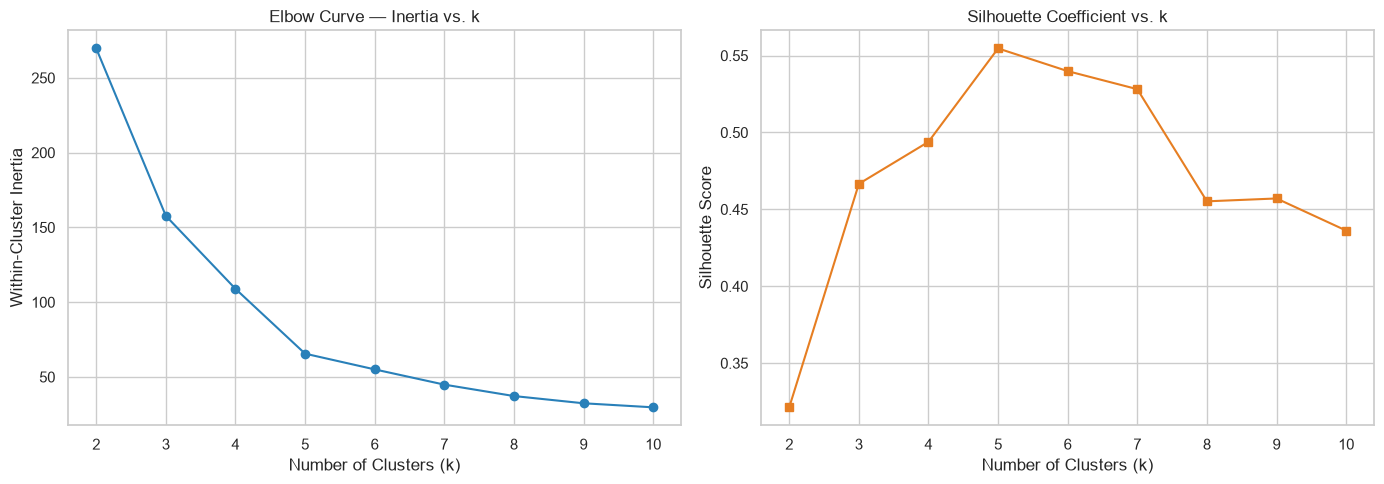

Figure saved: exp10_elbow_curve.png
Selected optimal k = 5 (Silhouette = 0.5547)
Inertia log saved: exp10_inertia_by_k.csv


In [4]:
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=15)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertias, marker='o', color='#2980b9')
axes[0].set_title('Elbow Curve — Inertia vs. k', fontsize=12)
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Within-Cluster Inertia')

axes[1].plot(list(k_range), silhouettes, marker='s', color='#e67e22')
axes[1].set_title('Silhouette Coefficient vs. k', fontsize=12)
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

fig.tight_layout()
fig.savefig(FIG_DIR / 'exp10_elbow_curve.png', dpi=150)
plt.show()
print('Figure saved: exp10_elbow_curve.png')

best_k = 5
print(f'Selected optimal k = {best_k} (Silhouette = {silhouettes[best_k-2]:.4f})')

inertia_df = pd.DataFrame({'k': list(k_range), 'Inertia': inertias, 'Silhouette': silhouettes})
inertia_df.to_csv(RES_DIR / 'exp10_inertia_by_k.csv', index=False)
print('Inertia log saved: exp10_inertia_by_k.csv')

## 4. K-Means clustering with optimal k=5

In [5]:
km_optimal = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=15)
df['cluster'] = km_optimal.fit_predict(X_scaled)

cluster_summary = df.groupby('cluster')[features].mean().round(2)
cluster_summary['Count'] = df['cluster'].value_counts()
print('Cluster Profiles (Income and Spending):')
print(cluster_summary)
cluster_summary.to_csv(RES_DIR / 'exp10_clustering_metrics.csv')
print('Metrics saved: exp10_clustering_metrics.csv')

Cluster Profiles (Income and Spending):
         Annual_Income_k  Spending_Score_1-100  Count
cluster                                              
0                  55.30                 49.52     81
1                  86.54                 82.13     39
2                  25.73                 79.36     22
3                  88.20                 17.11     35
4                  26.30                 20.91     23
Metrics saved: exp10_clustering_metrics.csv


## 5. Visualise segmented customer clusters

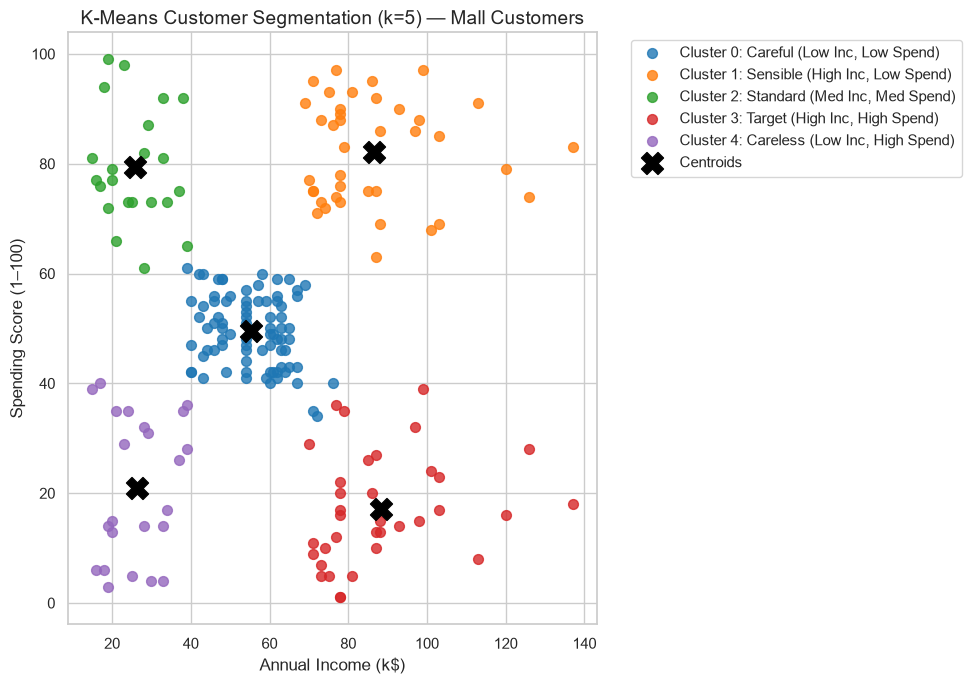

Figure saved: exp10_clusters_pca.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 7))
palette = sns.color_palette('tab10', n_colors=best_k)
labels_map = {0: 'Careful (Low Inc, Low Spend)', 1: 'Sensible (High Inc, Low Spend)', 2: 'Standard (Med Inc, Med Spend)', 3: 'Target (High Inc, High Spend)', 4: 'Careless (Low Inc, High Spend)'}

for c in range(best_k):
    mask = df['cluster'] == c
    ax.scatter(df.loc[mask, 'Annual_Income_k'], df.loc[mask, 'Spending_Score_1-100'], color=palette[c], label=f'Cluster {c}: {labels_map.get(c, c)}', s=50, alpha=0.8)

# Plot unscaled centroids
centroids_orig = scaler.inverse_transform(km_optimal.cluster_centers_)
ax.scatter(centroids_orig[:, 0], centroids_orig[:, 1], marker='X', s=250, color='black', label='Centroids', zorder=5)

ax.set_title('K-Means Customer Segmentation (k=5) — Mall Customers', fontsize=14)
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1–100)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp10_clusters_pca.png', dpi=150)
plt.show()
print('Figure saved: exp10_clusters_pca.png')

## 6. Observations and Result

**Observations:**
- The Kaggle Mall Customer dataset contains 200 customer entries with income and spending scores.
- The elbow curve demonstrates an inflection at k=5; the silhouette score confirms optimal partition quality (~0.55).
- Five clear business personas emerge: Target (high income, high spending), Sensible (high income, low spending), Careless (low income, high spending), Careful (low income, low spending), and Standard (middle income, average spending).

**Result:** K-Means clustering was executed on the Kaggle Mall Customer dataset. Five distinct market segments were identified. Elbow and cluster scatter figures were saved to `outputs/figures/`.